# Follow-along analysis: Indonesia's 2026 fire season with CAMS data

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ecmwf-training/2026-cams-act8-training/blob/main/cams-demo-indonesia-fire-season-act8-2026.ipynb)

**No local installation needed**: click the badge above to open and run this notebook in Google Colab. All you need is a Google account and a free ECMWF/ADS API token (see *Initial setup* below). Alternatively, you can of course run the full notebook on your own computer as well.

This is a practical end-to-end workflow to demonstrate accessing and visualising CAMS wildfire data. The goal is to give an overview and some code examples on how to combine the CAMS [Fire Emissions Watch](https://apps.atmosphere.copernicus.eu/) and the new Analysis-Ready, Cloud-Optimised (ARCO) datasets to get an overview of current and historical wildfire emission data. We will use the currently (Oct 2026) ongoing Indonesia wildfire season as an example, but the code can be easily adjusted for any other region or time period. A recent CAMS news article on this topic is available at https://atmosphere.copernicus.eu/copernicus-indonesias-seasonal-fires-intensify-boreal-wildfire-smoke-impacts-northern-hemisphere. 



## Initial setup

#### Atmosphere Data Store (ADS) key and licence 
In order to access the necessary data for this notebook, you need to follow these 3 easy steps:
- create a free [ECMWF account](https://www.ecmwf.int/)
- accept the dataset licenses at the bottom of the *Download* tab for [CAMS global forecasts](https://ads.atmosphere.copernicus.eu/datasets/cams-global-atmospheric-composition-forecasts?tab=download) and [ORAS5](https://cds.climate.copernicus.eu/datasets/reanalysis-oras5-timeseries?tab=download)
- finally, copy the API token from [your profile](https://ads.atmosphere.copernicus.eu/profile) to use in the cell below

In [1]:
import os
adsapi_key = "<INSERT-ADS-API-KEY-HERE>" # replace with your actual ADS API key from your user profile

# these are alternative methods to provide the ADS API key if it is not set directly in the script.
# you can ignore this if you already replaced the adsapi_key variable above.
if adsapi_key == "<INSERT-ADS-API-KEY-HERE>":
    adsapi_key = None
if adsapi_key is None:
    adsapi_key = os.getenv("ADSAPI_KEY")
if adsapi_key is None and os.path.exists(os.path.expanduser("~/.adsapirc")):
    with open(os.path.expanduser("~/.adsapirc"), "r") as f:
        for line in f:
            if line.startswith("key:"):
                adsapi_key = line.split(":")[1].strip()
                break
if adsapi_key is None:
    raise ValueError("ADSAPI key not found. Please set the ADSAPI_KEY environment variable or create a ~/.adsapirc file.")

TOKEN = adsapi_key   # the ADS token doubles as the Bearer token for the ARCO stores

#### Python packages
Install any missing packages via PIP (Python package manager). Available packages will be skipped automatically.

In [ ]:
! pip install xarray zarr aiohttp fsspec requests pandas matplotlib cartopy
# (or `conda env create -f environment.yml` ; see the environment file in the GitHub repository).

# Getting started
All initial set-up steps are now finished and we can finally start with analysing and visualising the data!

First, we will use the CAMS [Fire Emissions Watch](https://apps.atmosphere.copernicus.eu/fire-emissions-watch/) app to get an interactive overview of the current and historical wildfire emissions around the world. Launch the app in your web browser and start exploring, some questions to answer could be:

- Which countries dominate global fire emissions this week?
- How does the ranking change when you sort by intensity or anomaly?
- Which country had the highest total wildfire emissions in 2023?
- How does Indonesia’s 2026 season compare with its 2003–2025 average?
- Does wildfire smoke reach neighbouring countries?
- What Aerosol Optical Depth values are modelled for major cities in the region?

When you are done exploring, export the CSV data for Indonesia (download button in top left chart). This file is the starting point for a more in-depth analysis during the rest of the notebook.

# Outline

We will now analyse the exported CSV file for Indonesia in more depth and also combine our findings with information from further CAMS datasets to address the following questions:

1. How unusual are the current wildfire emissions?
2. Where is the smoke travelling?
3. Is there a link to El Niño?
4. Do the fires impact regional air quality?
5. Is this haze unusual?
6. What happens next?

## 1. How unusual are the current wildfire emissions?

Lets use the CSV file for Indonesia exported from CAMS Fire Emissions Watch to analyse the results in Python.

In [2]:
# standard imports used throughout the notebook
import urllib.request
from pathlib import Path
import warnings
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt, matplotlib.patheffects as pe
import cartopy.crs as ccrs, cartopy.feature as cfeature
import requests

# the CSV exported from Fire Emissions Watch. If you are working locally, point this
# variable to your local file. On Colab it is not present, so we download it from the repository.
CSV_FILE = Path("data/greece_cumulative_totals_by_year_carbon_emissions_from_wildfires_cams_gfas_v1_2_2026-10-19.csv")
if not CSV_FILE.exists():
    CSV_FILE.parent.mkdir(exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/ecmwf-training/2026-cams-act8-training/main/data/" + CSV_FILE.name,
        CSV_FILE)
    print(f"Downloaded {CSV_FILE.name}")

cumulative_emissions = pd.read_csv(CSV_FILE, skiprows=9, index_col=0).drop(columns="Mean (kg C)") / 1e9    # convert from kg C to Mt C (cumulative through the year)
cumulative_emissions.columns = cumulative_emissions.columns.str[:4].astype(int)

# lets inspect the data structure
print(cumulative_emissions) 

           2003      2004      2005      2006      2007      2008      2009  \
Date                                                                          
01-01  0.000000  0.000000  0.000000  0.000000  0.000000  0.000000  0.000000   
01-02  0.000000  0.000000  0.000000  0.000000  0.000000  0.000000  0.000000   
01-03  0.000000  0.000000  0.000000  0.000000  0.000000  0.000000  0.000000   
01-04  0.000000  0.000000  0.000000  0.000000  0.000000  0.000000  0.000000   
01-05  0.000000  0.000000  0.000000  0.000000  0.000000  0.000000  0.000000   
...         ...       ...       ...       ...       ...       ...       ...   
10-15  0.184594  0.185956  0.148532  0.269357  4.431396  0.442498  0.771639   
10-16  0.185110  0.186493  0.151123  0.269357  4.433759  0.444050  0.771845   
10-17  0.185110  0.190068  0.152324  0.270026  4.435224  0.447431  0.771845   
10-18  0.185395  0.194181  0.156789  0.270091  4.440861  0.448741  0.771845   
10-19  0.185395  0.195663  0.161070  0.270191  4.443

ValueError: The number of FixedLocator locations (10), usually from a call to set_ticks, does not match the number of labels (12).

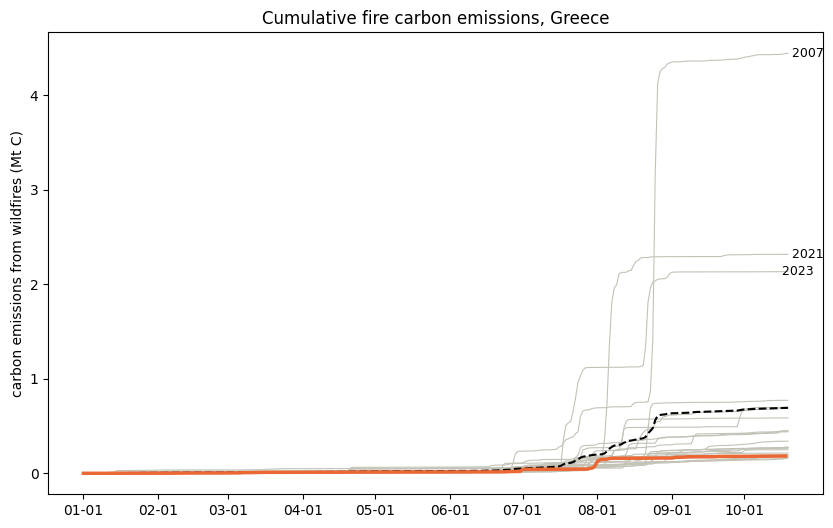

In [3]:
# lets recreate the cumulative fire carbon emissions plot for Indonesia as a sanity check
CURRENT_YEAR = 2026  
ACCENT, GREY = "#eb6834", "#c3c2b7" # plot settings for reuse

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(cumulative_emissions.index, cumulative_emissions, color=GREY, lw=0.8)
ax.plot(cumulative_emissions.index, cumulative_emissions.drop(columns=CURRENT_YEAR).mean(axis=1), "k--", lw=1.5, label="2003–2025 mean")
ax.plot(cumulative_emissions.index, cumulative_emissions[CURRENT_YEAR], color=ACCENT, lw=2.5, label=CURRENT_YEAR)
top3 = cumulative_emissions.max().nlargest(3)     # the three largest years overall
for year in top3.index:
    ax.text(cumulative_emissions[year].idxmax(), top3[year], f" {year}", va="center", fontsize=9)
ax.set(title="Cumulative fire carbon emissions, Greece", ylabel="carbon emissions from wildfires (Mt C)",
       xticks=cumulative_emissions.index[cumulative_emissions.index.str.endswith("-01")],
       xticklabels=list("JFMAMJJASOND"), xlim=("01-01", "12-31"))   # one label at the 1st of each month
ax.legend()

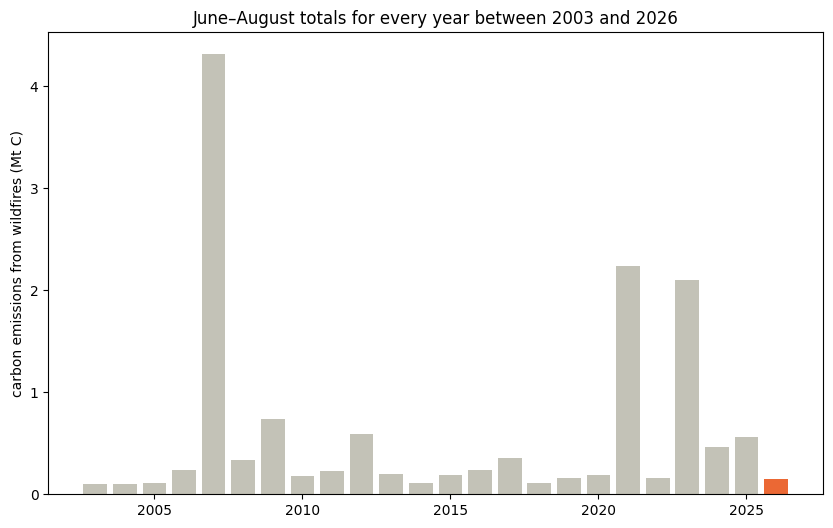

In [4]:
# and also compare this year's fire season (July–September) emissions with previous years
fig, ax_bar = plt.subplots(figsize=(10, 6))
jas_emissions = cumulative_emissions.loc["08-31"] - cumulative_emissions.loc["05-31"]
bar_colors    = [ACCENT if year == CURRENT_YEAR else GREY for year in jas_emissions.index]
ax_bar.bar(jas_emissions.index, jas_emissions, color=bar_colors)
ax_bar.set(title="June–August totals for every year between 2003 and 2026", ylabel="carbon emissions from wildfires (Mt C)");

## 2. Where is the smoke travelling?

So far we worked with GFAS data and a CSV exported by hand from Fire Emissions Watch. To bring in further gridded datasets, to e.g. look at air quality impacts, we have two options:
- Download GRIB or netCDF files from the [CAMS Atmosphere Data Store](https://ads.atmosphere.copernicus.eu) and import them here, or
- directly access the relevant subsets from the new **Analysis-Ready, Cloud-Optimised (ARCO)** datasets (still in Beta)

We will focus on using the ARCO data only for the rest of the notebook.

### Working with ARCO data

The Data Store Service at ECMWF offers a subset of some of the data available in the Data Stores in an ARCO format. These ARCO data are typically provided as Zarr archives stored in S3-compatible object storage that you open lazily. This means only metadata is read at first and only the chunks (i.e. subsets of the data) you actually need for your analysis are downloaded (cloud-optimised). Furthermore, datasets are available as single datacubes with consistent metadata, which means no files to decode, scale or merge beforehand (analysis-ready).

Data in a Zarr archive is stored in **chunks**, the smallest unit that can be transferred. To only download the smallest necessary data volumes for each use case, every dataset comes in two layouts:

| Layout | Chunked in… | Best for | Example |
|---|---|---|---|
| `geoChunked` | the spatial dimensions | long time series at one point or small area | time-series plots |
| `timeChunked` | the time dimension | large regions over a short period | maps |


<table><tr>
<td style="background-color:white; padding:8px">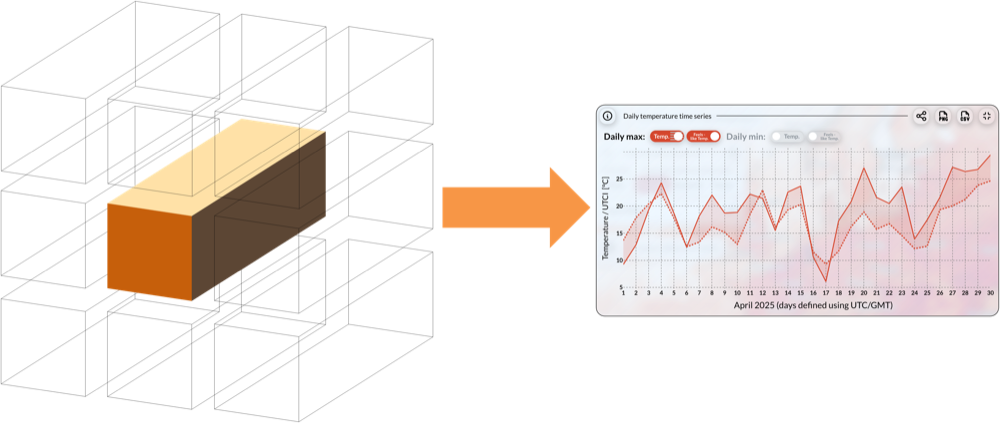<br><b>geo-chunked</b> — for time series</td>
<td style="background-color:white; padding:8px">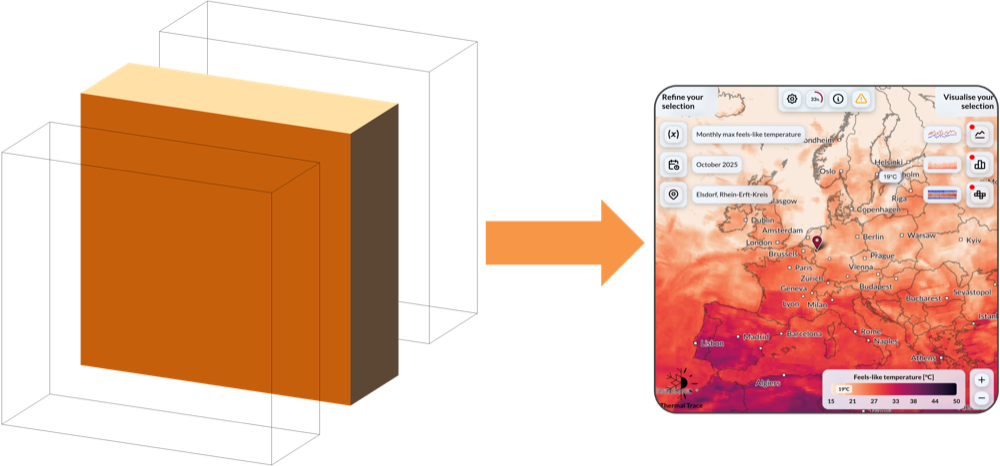<br><b>time-chunked</b> — for maps</td>
</tr></table>

The appropriate choice may appear counterintuitive: 
- For long time series at a single point or small area → use the geo-chunked Zarr archive. 
- For large spatial regions over short time periods → use the time-chunked Zarr archive.

Full documentation: [Analysis Ready Cloud Optimised (ARCO) Data](https://confluence.ecmwf.int/spaces/CKB/pages/639215345/Analysis+Ready+Cloud+Optimised+ARCO+Data).

In [5]:
# in this notebooks, we will combine data from 5 different ARCO datasets
CAMS_FORECAST_MAP           = "https://arco.datastores.ecmwf.int/cadl-arco-time-001/arco/cams_global_atmospheric_composition_forecasts/sfc-multiforecast/timeChunked.zarr"
CAMS_FORECAST_TIME_SERIES   = "https://arco.datastores.ecmwf.int/cadl-arco-geo-001/arco/cams_global_atmospheric_composition_forecasts/sfc-multiforecast/geoChunked.zarr"
CAMS_REANALYSIS_TIME_SERIES = "https://arco.datastores.ecmwf.int/cadl-arco-geo-010/arco/cams_global_reanalysis_eac4/sfc/geoChunked.zarr"
ORAS5_CONSOLIDATED          = "https://arco.datastores.ecmwf.int/cadl-arco-geo-001/arco/reanalysis_oras5/consolidated/geoChunked.zarr"   # consolidated: 1958–2014
ORAS5_OPERATIONAL           = "https://arco.datastores.ecmwf.int/cadl-arco-geo-001/arco/reanalysis_oras5/operational/geoChunked.zarr"    # operational: 2015–present

# these can be simply loaded using the following helper function and using your ADS API token for authentication.
def open_arco(url):
    return xr.open_zarr(url, consolidated=True,
                        storage_options={"headers": {"Authorization": f"Bearer {TOKEN}"}})



#### CAMS AOD forecast maps
Let's start simple. The CAMS global forecast datacube currently keeps every forecast since May 2026. It has two time dimensions: `time` is when a forecast was initialised (00 or 12 UTC), `time_step` is the forecast time step (i.e. lead time) in hours.

In [6]:
# lets open the ARCO datacube and confirm the metadata
forecast = open_arco(CAMS_FORECAST_MAP)
forecast

ImportError: The zarr package is required for working with Zarr stores but could not be imported. Please install it with your package manager (e.g. conda or pip).

 To get started, lets take yesterday's 00 UTC forecast and map its organic matter aerosol optical depth (AOD) 36 hours in, i.e. today at 12 UTC. The organic matter AOD is here used as a tracer for smoke resulting from wildfires and is drawn in the same way as the Fire Emissions Watch app shows it. We will also add location markers to show a couple of cities for orientation.

In [ ]:
# get example forecast field for today from yesterday's forecast
yesterday  = pd.Timestamp.now().normalize() - pd.Timedelta(days=1)  # yesterday's forecast, initialised at 00 UTC
lead_hours  = 36
aod_today   = forecast.omaod550.sel(time=yesterday, time_step=lead_hours) # select the organic matter AOD variable
valid_time = yesterday + pd.Timedelta(hours=lead_hours)              # 36 hours into that forecast: today, 12 UTC

# mimic colourmap from Fire Emissions Watch app with opacity ramp (optional)
rgba       = plt.cm.RdPu(np.linspace(0, 1, 256)); 
rgba[:, 3] = np.clip(np.linspace(0, 4, 256), 0, 1)  # fade in the opacity from 0 to 100% over the first quarter of the colourmap
cmap_aod = plt.matplotlib.colors.ListedColormap(rgba)

# the cities to mark on the map (optional)
CITIES = {"Thessaloniki": (40.64, 22.94)}
OFFSETS = {"Thessaloniki": (45, 25)}   # label positions, in points

def mark_cities(ax, face, text, halo):
    for city, (lat, lon) in CITIES.items():
        ax.plot(lon, lat, "o", transform=ccrs.PlateCarree(), ms=7, mfc=face, mec=halo, mew=1.2, zorder=5)
        dx, dy = OFFSETS[city]
        ax.annotate(city, (lon, lat), xycoords=ccrs.PlateCarree()._as_mpl_transform(ax), xytext=(dx, dy), textcoords="offset points",
                    ha="left" if dx > 0 else "right", fontsize=9, color=text, zorder=6,
                    path_effects=[pe.withStroke(linewidth=2.5, foreground=halo)],
                    arrowprops=dict(arrowstyle="-", lw=0.6, color=text, alpha=0.7))


warnings.filterwarnings("ignore", category=RuntimeWarning, module="shapely")   # cartopy projects shapes beyond the horizon to NaN

# create orthographic plot of forecasted AOD field 
with plt.style.context("dark_background"): # white text on dark background
    ax = plt.figure(figsize=(12, 12)).add_subplot(projection=ccrs.Orthographic(122, 3), facecolor="#141414")
    aod_today.plot.imshow(ax=ax, transform=ccrs.PlateCarree(), cmap=cmap_aod, vmin=0, vmax=1, interpolation="bilinear",
                      cbar_kwargs={"orientation": "horizontal", "shrink": 0.4, "pad": 0.03, "ticks": [0, 0.5, 1],
                                   "label": "Organic matter AOD at 550 nm"})
    ax.spines["geo"].set_visible(False); 
    ax.add_feature(cfeature.LAND, fc="#2b2b2b")
    ax.add_feature(cfeature.BORDERS, ec="#555555", lw=0.5); 
    ax.coastlines(color="#555555", lw=0.5)
    mark_cities(ax, face="#4FC6E0", text="white", halo="#141414")
    ax.set_title(f"Forecast valid for {valid_time:%d %b %Y %H}UTC (initialised {yesterday:%d %b %H}UTC)", fontsize=12)



## 3. · Is there a link to El Niño?
Fire seasons in Indonesia are worst during years with strong El Niño events. 

To test this relation, we first need a time series of the [Niño 3.4 index](https://www.ncei.noaa.gov/access/monitoring/enso/sst/), which is the sea-surface temperature (SST) anomaly in a box of the equatorial Pacific, for the same time period as our fire emissions data. For this, we simply add another ARCO dataset from the Coperncius Climate Change Service (C3S): the [ORAS5 global ocean reanalysis](https://cds.climate.copernicus.eu/datasets/reanalysis-oras5-timeseries?tab=overview). We can then select the SST data and calculate the Niño 3.4 index ourselve:

In [ ]:
# ORAS5 is a monthly dataset and includes two production streams: consolidated (1958–2014) and operational (2015–present)
# see https://cds.climate.copernicus.eu/datasets/reanalysis-oras5-timeseries?tab=overview for full documentation.
# lets merge the full record first
nino34_region = dict(latitude=slice(-5, 5), longitude=slice(-170, -120))
sst_first_years = open_arco(ORAS5_CONSOLIDATED).sosstsst.sel(**nino34_region)
sst_last_years  = open_arco(ORAS5_OPERATIONAL).sosstsst.sel(**nino34_region)
sst = xr.concat([sst_first_years, sst_last_years], dim="time")

print(sst)

In [ ]:
# calculate Niño 3.4 index for July–September (JAS)
nino34_monthly  = sst.mean(["latitude", "longitude"]).to_series()                 # full monthly index, 1958–present
nino34_jas_only = nino34_monthly[nino34_monthly.index.month.isin([7, 8, 9])]
nino34_jas_full = nino34_jas_only.groupby(nino34_jas_only.index.year).mean()      # JAS mean, every year
nino34_full_anomaly = nino34_jas_full - nino34_jas_full.mean()                    # anomaly against the full-record mean

nino34_jas     = nino34_jas_full.loc[jas_emissions.index[0]:]                     # just the years we have GFAS emissions for (2003–present)
nino34_anomaly = nino34_jas - nino34_jas.mean()                                   # how much warmer/cooler than the 2003–present average

fig, ax = plt.subplots(figsize=(14, 6))
RED = "#c0392b"
BLUE = "#1f4e9c"
ax.bar(nino34_full_anomaly.index, nino34_full_anomaly, color=np.where(nino34_full_anomaly > 0, RED, BLUE))
ax.axvspan(jas_emissions.index[0] - 0.5, jas_emissions.index[-1] + 0.5, color=GREY, alpha=0.3, zorder=0)   # years with GFAS fire data
ax.axhline(0, color="k", lw=0.6)
ax.set(title="SST anomaly for Niño 3.4 region from ORAS5, July–September, 1958–present", ylabel="SST anomaly (°C)")

In [ ]:
# now lets look at a simple scatter plot of this index against the Indonesian fire  emissions
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(nino34_anomaly, jas_emissions, s=5 * jas_emissions, c=bar_colors, edgecolor="w")   # circle area follows the emissions

for year in jas_emissions.index: # lets add some year labels
    ax.annotate(f"{year % 100:02d}", (nino34_anomaly[year], jas_emissions[year]), (0, jas_emissions[year] ** 0.5 + 2),
                textcoords="offset points", ha="center", fontsize=7)
xtitle, ytitle = ax.set(xlabel="Niño 3.4 anomaly, July–September (°C)", ylabel="Total wildfire carbon emissions, July–September (Mt C)")

## 4. Do the fires impact regional air quality?
Lets analyse how the ongoing wildfire season in Indonesia is affecting local and regional air quality. For this, we can access the time-series-optimised ARCO file of the CAMS global forecast. This allows us to quickly access a long time series of forecast values for just those grid points around a location of interest (our cities in this case). In addition to the organic matter AOD, we now also include PM2.5 surface concentrations in our request to compare the forecast with air quality guidelines from the World Health Organisation (WHO). 

In [ ]:
cities = pd.DataFrame(CITIES, index=["latitude", "longitude"]).T.rename_axis("city").to_xarray() # same cities from before

city_forecasts = open_arco(CAMS_FORECAST_TIME_SERIES)[["pm2p5", "omaod550"]].sel(cities, method="nearest").load()    # grid box nearest to each city

print(city_forecasts)

In [ ]:
city_forecasts["pm2p5"] = city_forecasts.pm2p5 * 1e9 # convert to µg m-3

# compute daily mean for each city from the first 24 hours of each 00 UTC forecast run
daily_mean = city_forecasts.isel(time=city_forecasts.time.dt.hour == 0).sel(time_step=slice(0, 23)).mean("time_step")   

In [ ]:
# plot daily-mean surface PM2.5 and organic matter AOD for each city

WHO_LEVELS  = [0, 15, 25, 37.5, 50, 75, 1e5]   # WHO AQ guideline and interim targets for 24-hour mean PM2.5 exposure
BAND_COLORS = ["#A8DCF0", "#9AD3AC", "#EFBC3E", "#E56A32", "#C63447", "#74235B"]
BLUE  = "#1f4e9c"

fig, axes = plt.subplots(2, 3, figsize=(16, 7.5), sharex=True, layout="constrained")
for ax, city in zip(axes.flat, CITIES):

    # background shading for WHO levels
    pm25 = daily_mean.pm2p5.sel(city=city)
    ax.set(title=city, ylim=(0, 1.05 * pm25.max().item()), ylabel="PM2.5 (µg m$^{-3}$)")
    for low, high, shade in zip(WHO_LEVELS[:-1], WHO_LEVELS[1:], BAND_COLORS):
        ax.axhspan(low, high, color=shade, alpha=0.6, lw=0)

    # plot organic matter AOD on the right y-axis
    right = ax.twinx()
    right.plot(daily_mean.time, daily_mean.omaod550.sel(city=city), color=BLUE, lw=1.5)
    right.set_ylabel("Organic matter AOD at 550 nm", color=BLUE); right.set_ylim(bottom=0)
    right.tick_params(axis="y", colors=BLUE); right.spines["right"].set(visible=True, color=BLUE)

    # a third layer, so the PM2.5 line lies above the AOD line
    top = ax.twinx();
    top.set_ylim(ax.get_ylim()); 
    top.axis("off")        
    top.plot(daily_mean.time, pm25, "k", lw=1.5)
    
fig.suptitle("CAMS daily-mean surface PM2.5 (black and against WHO targets) and organic matter AOD (blue)", fontsize=13);

## 5. Is this haze unusual?
Let's pick one of the worst-affected cities (Palangkaraya) and look at the local air quality over past fire seasons. CAMS provides a global reanalysis of atmospheric composition back to 2003. Reanalysis combines model data with observations from across the world into a globally complete and consistent dataset using a model of the atmosphere based on the laws of physics and chemistry. A subset of variables, including surface PM2.5, is also available as an ARCO datacube. We can use this to retrive the local air quality data for Palangkaraya with 3-hourly resolution easily:

In [ ]:
lat, lon = CITIES["Palangkaraya"]
pm25_reanalysis = open_arco(CAMS_REANALYSIS_TIME_SERIES).pm2p5.sel(latitude=lat, longitude=lon, method="nearest").load() * 1e9   # 23 years, 3-hourly

print(pm25_reanalysis)

In [ ]:
# let's use this data to create a daily-mean PM2.5 heatmap for Palangkaraya

# prepare the data
pm25_reanalysis = pm25_reanalysis.resample(time="1D").mean().to_series()       # daily means
stripes = pm25_reanalysis.groupby([pm25_reanalysis.index.year, pm25_reanalysis.index.dayofyear]).mean().unstack()  # one row per year, one column per day

# create the heatmap
fig, ax = plt.subplots(figsize=(9, 6.4), layout="constrained")
image = ax.pcolormesh(stripes.columns, stripes.index, stripes.values, cmap="magma_r", vmin=0, vmax=600)       # colour scale capped at 600 µg m-3
ax.set(title="Palangkaraya: daily-mean PM2.5 since 2003", yticks=range(2003, 2026, 2), xticks=pd.date_range("2025-01-01", periods=12, freq="MS").dayofyear, xticklabels=list("JFMAMJJASOND"))
fig.colorbar(image, ax=ax, location="bottom", shrink=0.5, extend="max", label="PM2.5 (µg m$^{-3}$)")

In [ ]:
# let's combine the heatmap with the Niño 3.4 data to directly see the relationship between PM2.5 and ENSO
fig, (ax, ax_enso) = plt.subplots(1, 2, figsize=(12, 6.4), width_ratios=(10, 1.5), sharey=True, layout="constrained")

# first, redraw the heatmap 
image = ax.pcolormesh(stripes.columns, stripes.index, stripes.values, cmap="magma_r", vmin=0, vmax=600)       # colour scale capped at 600 µg m-3
ax.set(title="Palangkaraya: daily-mean PM2.5 since 2003", yticks=range(2003, 2026, 2), xticks=pd.date_range("2025-01-01", periods=12, freq="MS").dayofyear, xticklabels=list("JFMAMJJASOND"))
fig.colorbar(image, ax=ax, location="bottom", shrink=0.5, extend="max", label="PM2.5 (µg m$^{-3}$)")

# add the Niño 3.4 anomaly bar chart for the EAC4 time period
nino34_hist = nino34_anomaly.loc[2003:2025]      # July–September Niño 3.4 from section 3
ax_enso.barh(nino34_hist.index, nino34_hist.values, color=np.where(nino34_hist > 0, RED, BLUE))
ax_enso.axvline(0, color="k", lw=0.6)
ax_enso.set(title="Niño 3.4, Jul–Sep", xlabel="Anomaly (°C)", xlim=(-2, 2))
ax_enso.tick_params(left=False)

## 6. What happens next?

In [ ]:
# finally, let's use the CAMS forecast to create an animation of regional air quality (PM2.5 concentrations) over the next five days

# we will use Matplotlib's built-in animation capabilities
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# region of interest
REGION = dict(latitude=slice(-15, 20), longitude=slice(90, 150))
plt.rcParams["animation.frame_format"] = "jpeg"                                # JPEG frames halve the file size

# prepare the data
latest_run   = pd.Timestamp(city_forecasts.dropna("time").time.values[-1])      # get most recent forecast run
hourly_pm25  = forecast.pm2p5.sel(time=latest_run, **REGION).load() * 1e9       # get hourly forecast fields for the next 5 days
rolling_pm25 = hourly_pm25.rolling(time_step=24).mean().sel(time_step=slice(24, None))   # trailing 24-hour mean for WHO targets, from +24 h onwards

# define the actual plot
ax = plt.figure(figsize=(12, 8), dpi=100, layout="constrained").add_subplot(projection=ccrs.PlateCarree())
image = rolling_pm25[0].plot.imshow(ax=ax, levels=WHO_LEVELS, colors=BAND_COLORS, add_labels=False, interpolation="bilinear",
                              interpolation_stage="data", cbar_kwargs={"orientation": "horizontal", "shrink": 0.7, "aspect": 22,
                                                                       "ticks": WHO_LEVELS[:-1], "label": "24-hour rolling mean PM2.5 (µg m$^{-3}$)"})
ax.coastlines("50m", lw=1, color="0.2")
ax.add_feature(cfeature.BORDERS.with_scale("50m"), lw=0.5, ec="0.3")
mark_cities(ax, face="0.15", text="black", halo="white")

# function to update the plot for each animation frame
def show(step):
    image.set_data(rolling_pm25[step])
    hour = int(rolling_pm25.time_step[step])
    ax.set_title(f"CAMS 24-hour rolling mean PM2.5, ending {latest_run + pd.Timedelta(hours=hour):%a %d %b %Y, %H UTC}\n"
                 f"initialised {latest_run:%d %b %Y, %H UTC}, +{hour} h", fontsize=13)

# create and display the animation
movie = FuncAnimation(ax.figure, show, frames=len(rolling_pm25), interval=150).to_jshtml(); plt.close()
HTML(movie)